# Array scaling overview: 20x, 10 m equivalent, 30 m equivalent

LFAST is replicated in arrays of 20 unit telescopes. The nominal Kitt Peak array (20 x 0.726 m,
8.3 m$^2$) has the collecting area of a **3.2 m** telescope; 10 arrays (200 telescopes) match a
**10.3 m** aperture and 86 arrays (1720 telescopes) a **30.1 m** aperture. This notebook sets up
the scaling model used by the science-case notebooks 07-10 and produces the headline sensitivity
curves.

**How arrays combine in the ETC.** Each 20-to-1 fiber combiner feeds one spectrograph input.
Within an array, star *and* sky electrons scale with the number of telescopes while detector
noise is paid once, so the SNR gain is better than $\sqrt{N}$ when read noise or dark current
matter. Beyond 20, the ETC assumes one input per array, co-added incoherently, so the SNR grows as
$\sqrt{n_{arrays}}$ on top of the single-array value (`Telescope(..., telescopes_per_input=20)`).
An idealised single combiner (`telescopes_per_input=None`) is shown dotted where it matters.

**Caveat.** This is a photon-budget scaling only. It assumes the spectrographs scale with the
arrays (one input per array on the same or replicated spectrographs), that the per-array
throughput stays at the Choi et al. (2026) values, and that sky subtraction, flat-fielding and
fiber-combiner stability do not limit faint-end performance. Multiplexing is not modelled: all
telescopes point at **one target** at a time.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from lfast_etc import LFASTETC, Source, Telescope, Instrument, list_instruments
from lfast_etc.plotting import plot_snr_map, plot_limiting_magnitude
try:
    plt.style.use('gks')
except OSError:
    pass

In [2]:
# ---- knobs: array sizes compared throughout (replicated in arrays of 20) ----
SCALES = {20: "nominal 20x (3.2 m eq.)", 200: "10 arrays (10.3 m eq.)", 1720: "86 arrays (30.1 m eq.)"}
NS = np.array([20, 40, 60, 100, 200, 400, 600, 1000, 1720, 2500])
FIG = "../memo/figures/"      # memo figures are saved here as PDF
plt.rcParams.update({"font.size": 11, "axes.titlesize": 10, "legend.fontsize": 9})
def tel(n, telescopes_per_input=20):
    return Telescope(n_telescopes=int(n), fiber="18um", combine="fiber", telescopes_per_input=telescopes_per_input)
def deq(n):
    return 0.726*np.sqrt(n)

## Equivalent apertures

In [3]:
print(f"{'N tel':>6} {'arrays':>7} {'area m2':>8} {'D_eq m':>7} {'inputs':>7}")
for n in NS:
    t = tel(int(n))
    print(f"{n:6d} {-(-n//20):7d} {t.total_area_m2:8.1f} {t.equivalent_diameter_m:7.1f} {t.n_inputs:7d}")

 N tel  arrays  area m2  D_eq m  inputs
    20       1      8.3     3.2       1
    40       2     16.6     4.6       2
    60       3     24.8     5.6       3
   100       5     41.4     7.3       5
   200      10     82.8    10.3      10
   400      20    165.6    14.5      20
   600      30    248.4    17.8      30
  1000      50    414.0    23.0      50
  1720      86    712.0    30.1      86
  2500     125   1034.9    36.3     125


## Limiting magnitude versus array size, both instruments

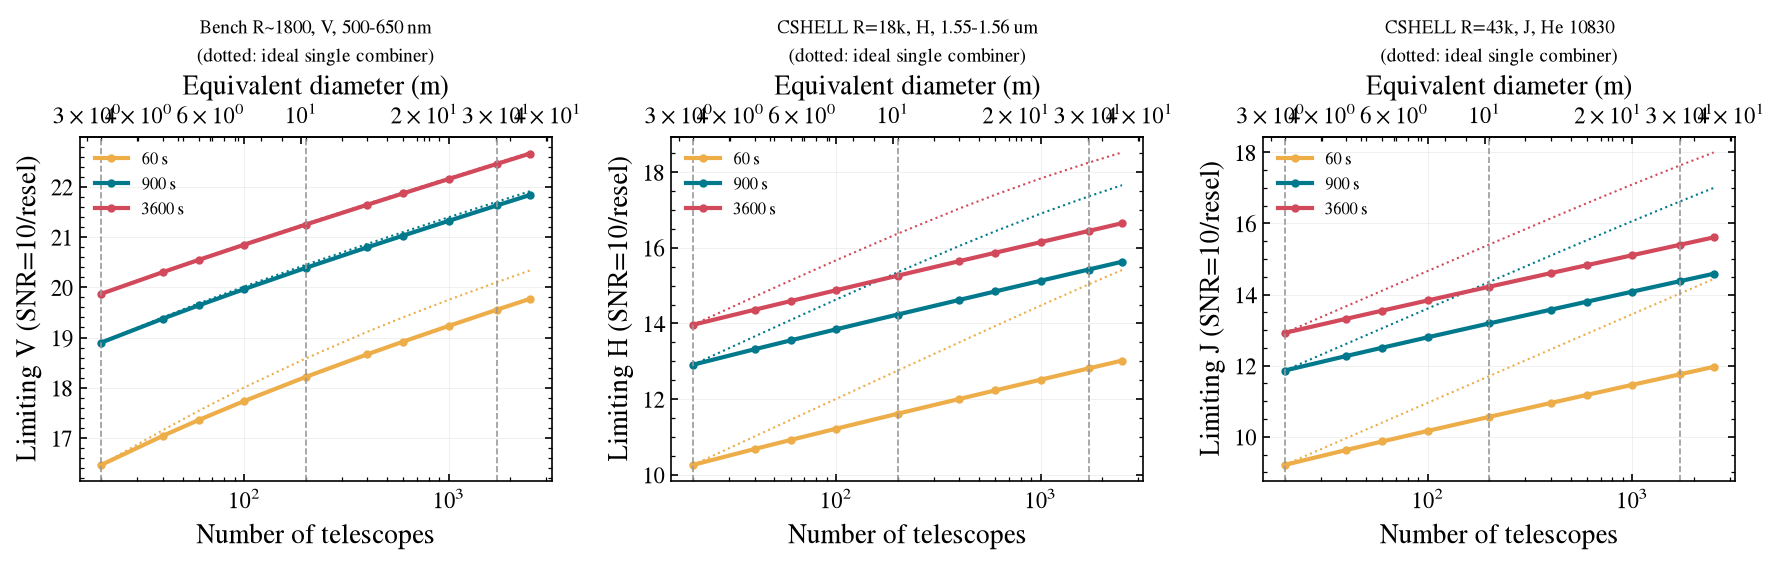

In [4]:
gstar = Source.blackbody(5800, 0, "V")
kstar = Source.blackbody(4500, 0, "H")
cases = {
    "Bench R~1800, V, 500-650 nm": ("bench_r1800", gstar, dict(), (500, 650)),
    "CSHELL R=18k, H, 1.55-1.56 um": ("cshell_r18000", kstar, dict(wavelength_min_nm=1550, wavelength_max_nm=1560), None),
    "CSHELL R=43k, J, He 10830": ("cshell_r43000", Source.blackbody(4800, 0, "J"), dict(wavelength_min_nm=1081, wavelength_max_nm=1086), 1083.3),
}
fig, axes = plt.subplots(1, 3, figsize=(12, 3.9))
summary = {}
for ax, (label, (preset, src, kw, win)) in zip(axes, cases.items()):
    for exp, color in ((60, 'C2'), (900, 'C0'), (3600, 'C1')):
        lim = [LFASTETC(preset, telescope=tel(int(n)), **kw).limiting_magnitude(src, exp, 10, wavelength=win) for n in NS]
        ideal = [LFASTETC(preset, telescope=tel(int(n), telescopes_per_input=None), **kw).limiting_magnitude(src, exp, 10, wavelength=win) for n in NS]
        ax.plot(NS, lim, marker='o', ms=3, color=color, label=f"{exp} s")
        ax.plot(NS, ideal, ls=':', color=color, lw=1)
        summary[(label, exp)] = dict(zip(NS, lim))
    for n in (20, 200, 1720):
        ax.axvline(n, color='0.6', ls='--', lw=0.8)
    ax.set_xscale('log'); ax.set_xlabel("Number of telescopes"); ax.set_ylabel(f"Limiting {src.band} (SNR=10/resel)")
    ax.set_title(label + "\n(dotted: ideal single combiner)", fontsize=9); ax.legend(fontsize=8)
    sec = ax.secondary_xaxis('top', functions=(deq, lambda d: (d/0.726)**2)); sec.set_xlabel("Equivalent diameter (m)")
plt.tight_layout(); fig.savefig(FIG + "limiting_mag_vs_N.pdf")

In [5]:
print("Limiting magnitude, SNR=10 per resel:")
for (label, exp), d in summary.items():
    print(f"{label:32s} {exp:5d} s: " + "  ".join(f"N={n}: {d[n]:5.2f}" for n in (20, 200, 1720)))

Limiting magnitude, SNR=10 per resel:
Bench R~1800, V, 500-650 nm         60 s: N=20: 16.47  N=200: 18.22  N=1720: 19.55
Bench R~1800, V, 500-650 nm        900 s: N=20: 18.90  N=200: 20.39  N=1720: 21.63
Bench R~1800, V, 500-650 nm       3600 s: N=20: 19.87  N=200: 21.25  N=1720: 22.45
CSHELL R=18k, H, 1.55-1.56 um       60 s: N=20: 10.26  N=200: 11.61  N=1720: 12.81
CSHELL R=18k, H, 1.55-1.56 um      900 s: N=20: 12.91  N=200: 14.23  N=1720: 15.43
CSHELL R=18k, H, 1.55-1.56 um     3600 s: N=20: 13.96  N=200: 15.26  N=1720: 16.44
CSHELL R=43k, J, He 10830           60 s: N=20:  9.21  N=200: 10.56  N=1720: 11.76
CSHELL R=43k, J, He 10830          900 s: N=20: 11.86  N=200: 13.19  N=1720: 14.38
CSHELL R=43k, J, He 10830         3600 s: N=20: 12.92  N=200: 14.22  N=1720: 15.40


## How the gain is split: source-, sky- and read-noise-limited regimes

At fixed SNR the required exposure time scales as $1/N$ in every regime once the array count
grows (incoherent co-add of inputs), and *faster* than $1/N$ inside a single array when detector
noise matters. The magnitude gain at fixed time is 2.5 log$_{10} N$ when source-limited and
1.25 log$_{10} N$ when background-limited, so the faint-end gain from 20 to 1720 telescopes is
between 2.4 and 4.8 mag.

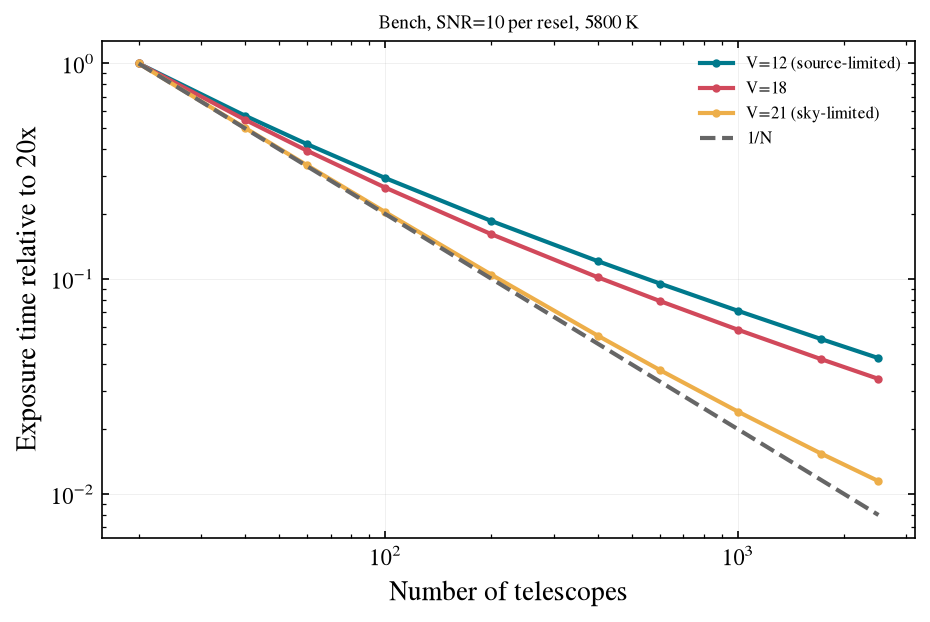

In [6]:
fig, ax = plt.subplots(figsize=(7, 4.3))
for mag, label in ((12, "V=12 (source-limited)"), (18, "V=18"), (21, "V=21 (sky-limited)")):
    t = [LFASTETC("bench_r1800", telescope=tel(int(n))).exptime_vs_mag(gstar, [mag], snr=10, wavelength=(500, 650))[0] for n in NS]
    ax.plot(NS, np.array(t)/t[0], marker='o', ms=3, label=label)
ax.plot(NS, 20/NS, color='0.4', ls='--', label="1/N")
ax.set_xscale('log'); ax.set_yscale('log'); ax.set_xlabel("Number of telescopes"); ax.set_ylabel("Exposure time relative to 20x")
ax.legend(fontsize=8); ax.set_title("Bench, SNR=10 per resel, 5800 K", fontsize=9)
fig.savefig(FIG + "exptime_scaling.pdf")

## Bright end: saturation

With one combiner input per 20-telescope array, the light per detector pixel is set by a single
array and does **not** grow with the number of arrays, so the bright limit is the same at 20, 200
and 1720 telescopes (an idealised single combiner would instead saturate N/20 times sooner). The
table gives the brightest star for which a 1 s (Bench) or 8 s (CSHELL, Fowler minimum) read stays
below 80% of full well (placeholder full wells).

In [7]:
for preset, band, teff, kw, tmin in (("bench_r1800", "V", 5800, {}, 1.0), ("cshell_r18000", "H", 4500, dict(wavelength_min_nm=1550, wavelength_max_nm=1560), 8.0)):
    row = []
    for n in (20, 200, 1720):
        e = LFASTETC(preset, telescope=tel(n), **kw)
        mags = np.arange(-2, 14, 0.1)
        peak = np.array([np.nanmax(e.snr(Source.blackbody(teff, m, band), tmin).peak_e_per_pixel) for m in mags])
        ok = mags[peak < 0.8*e.instrument.full_well]
        row.append(f"N={n}: {band}>{ok.min():.1f}")
    print(f"{preset:14s} ({tmin:.0f} s read): " + "   ".join(row))

bench_r1800    (1 s read): N=20: V>4.7   N=200: V>4.7   N=1720: V>4.7
cshell_r18000  (8 s read): N=20: H>1.7   N=200: H>1.7   N=1720: H>1.7
